## Autoencoder for Spectral Data

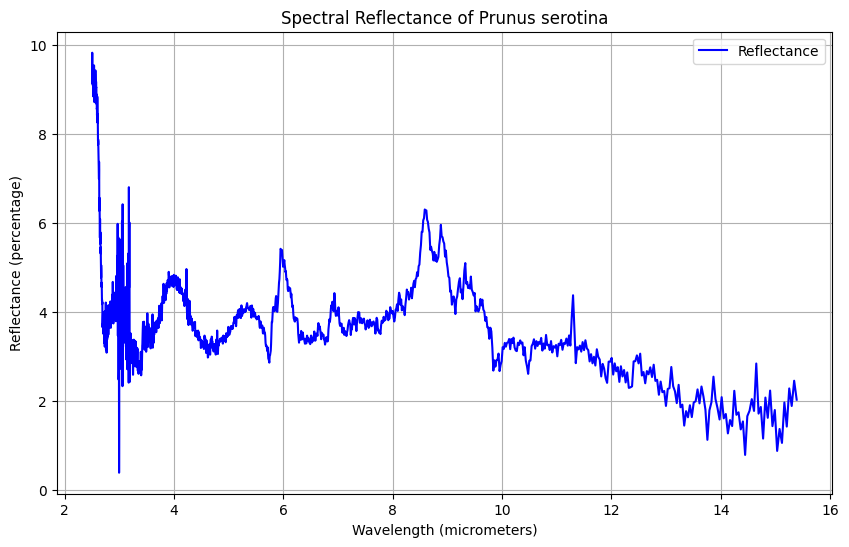

{
    "Name": "Prunus serotina",
    "Type": "Vegetation",
    "Class": "Tree",
    "Genus": "Prunus",
    "Species": "serotina",
    "Sample No.": "PRSE-2-65",
    "Owner": "UCSB",
    "Wavelength Range": "TIR",
    "Origin": "USA; Massachusetts; Harvard Forest",
    "Collection Date": "7/8/2013",
    "Description": "Samples were collected as part of NSF Macrosystem Biology proposal titled: Collaborative Research: Thermal controls on ecosystem metabolism and function: scaling from leaves to canopies to regions. Samples were collected and overnighted to JPL facilities for processing. The same leaves were processed in the Nicolet and then measured using the ASD.",
    "Measurement": "Hemispherical reflectance",
    "First Column": "X",
    "Second Column": "Y",
    "X Units": "Wavelength (micrometers)",
    "Y Units": "Reflectance (percentage)",
    "First X Value": "2.501",
    "Last X Value": "15.387",
    "Number of X Values": "1737",
    "Additional Information": "vegetation.tree.pr

In [1]:
from net.spec_utils import parse_spectral_file
import matplotlib.pyplot as plt
import json 


spectra_file = 'vegetation.tree.prunus.serotina.tir.prse-2-65.ucsb.nicolet.spectrum.txt'
spectra_files_dir = 'ecospeclib-all'
metadata, wavelengths, reflectances = parse_spectral_file(spectra_file, spectra_files_dir)

# Plotting the spectral data
plt.figure(figsize=(10, 6))
plt.plot(wavelengths, reflectances, label="Reflectance", color='blue')
plt.xlabel(metadata['X Units'])
plt.ylabel(metadata['Y Units'])
plt.title(f"Spectral Reflectance of {metadata['Name']}")
plt.grid(True)
plt.legend()
plt.show()
print(json.dumps(metadata, indent=4))

In [5]:
from net.spec_utils import read_and_preprocess_spectral_data
from net.spec_net import spec_AE
import numpy as np
from sklearn.model_selection import train_test_split


# Load and preprocess spectral data
X_data_normalized = read_and_preprocess_spectral_data(spectra_files_dir)
X_data_normalized = X_data_normalized.reshape((*X_data_normalized.shape, 1))

# Split data into training, validation, and test sets
X_train, X_test = train_test_split(X_data_normalized, test_size=0.3, random_state=42)
X_train, X_val = train_test_split(X_train, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test.shape}")

# Define the input shape
num_features = X_data_normalized.shape[1]
spectra_input_shape = (num_features, 1)
print(f"Number of features: {num_features}")

spectral_AE, spec_latent = spec_AE(spectra_input_shape, learning_rate=0.01, dropout_rate=0.3, l2_penalty=0.001)

Found 3451 spectral files
Training set shape: (1932, 224, 1)
Validation set shape: (483, 224, 1)
Test set shape: (1036, 224, 1)
Number of features: 224


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (1, 224, 1)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (1, 224, 16)           │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (1, 112, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 112, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (1, 112, 8)            │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (1, 56, 8)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (1, 56, 8)             │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (1, 112, 8)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 112, 8)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (1, 112, 16)           │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (1, 224, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (1, 224, 1)            │            49 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,105 (4.32 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
from net.spec_net import reduce_lr, early_stopping

spectral_AE.fit(X_train, X_train, epochs=100, batch_size=32, validation_data=(X_val, X_val), callbacks=[reduce_lr])

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0043 - val_loss: 0.2349 - learning_rate: 0.0010
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0059 - val_loss: 0.2257 - learning_rate: 0.0010
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0040 - val_loss: 0.2358 - learning_rate: 0.0010
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0058 - val_loss: 0.2342 - learning_rate: 0.0010
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0040 - val_loss: 0.2390 - learning_rate: 0.0010
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0110 - val_loss: 0.2581 - learning_rate: 0.0010
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0067 - val_loss: 0.2419 - learning_rate: 0.0010
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0076 - val_loss: 0.2355 - learning_rate: 0.0010
Epoch 9/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0042 - val_loss: 0.2320 - learning_rate: 0.0010
Epoch 10/100
61/61 

In [9]:
spectral_AE.save('models/spectral_AE.keras')

## 3D-Autoencoder for Hyperspectral Images

Datasets loaded:
Training annotations: dict_keys(['id', 'fruit', 'side', 'day', 'camera_type', 'files']) 636
Validation annotations: dict_keys(['id', 'fruit', 'side', 'day', 'camera_type', 'files']) 123
Test annotations: dict_keys(['id', 'fruit', 'side', 'day', 'camera_type', 'files']) 259
Input Shape: (64, 64, 224)


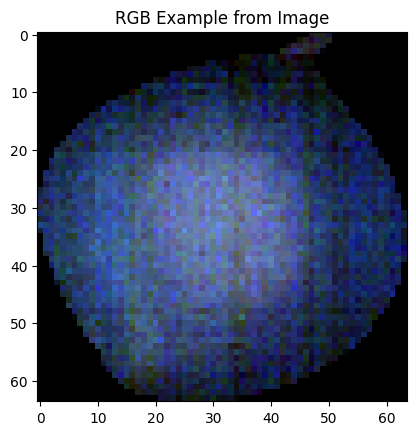

In [13]:
from net import hsi_utils
import matplotlib.pyplot as plt

# Path to DeepHS dataset
DeepHS_dir = 'DeepHS'
# Using existing splits from DeepHS dataset
training_annotations, validation_annotations, test_annotations = hsi_utils.load_DeepHS_images(DeepHS_dir)

# Sample File
max_bands = 224  # Adjust as necessary
data_file = training_annotations['records'][500]["files"]["data_file"]
hdr_file = training_annotations['records'][500]["files"]["header_file"]

hs_image, rgb_example = hsi_utils.read_and_visualize_hyperspectral_image(DeepHS_dir, data_file, hdr_file, max_bands)
print(f'Input Shape: {hs_image.shape}')

plt.imshow(rgb_example)
plt.title('RGB Example from Image')
plt.show()

Batch size: 32
Selected fruits: ['Mango', 'Kaki', 'Papaya', 'Kiwi', 'Avocado']
Total batches: 20
Shape of X_batch: (32, 64, 64, 224, 1)


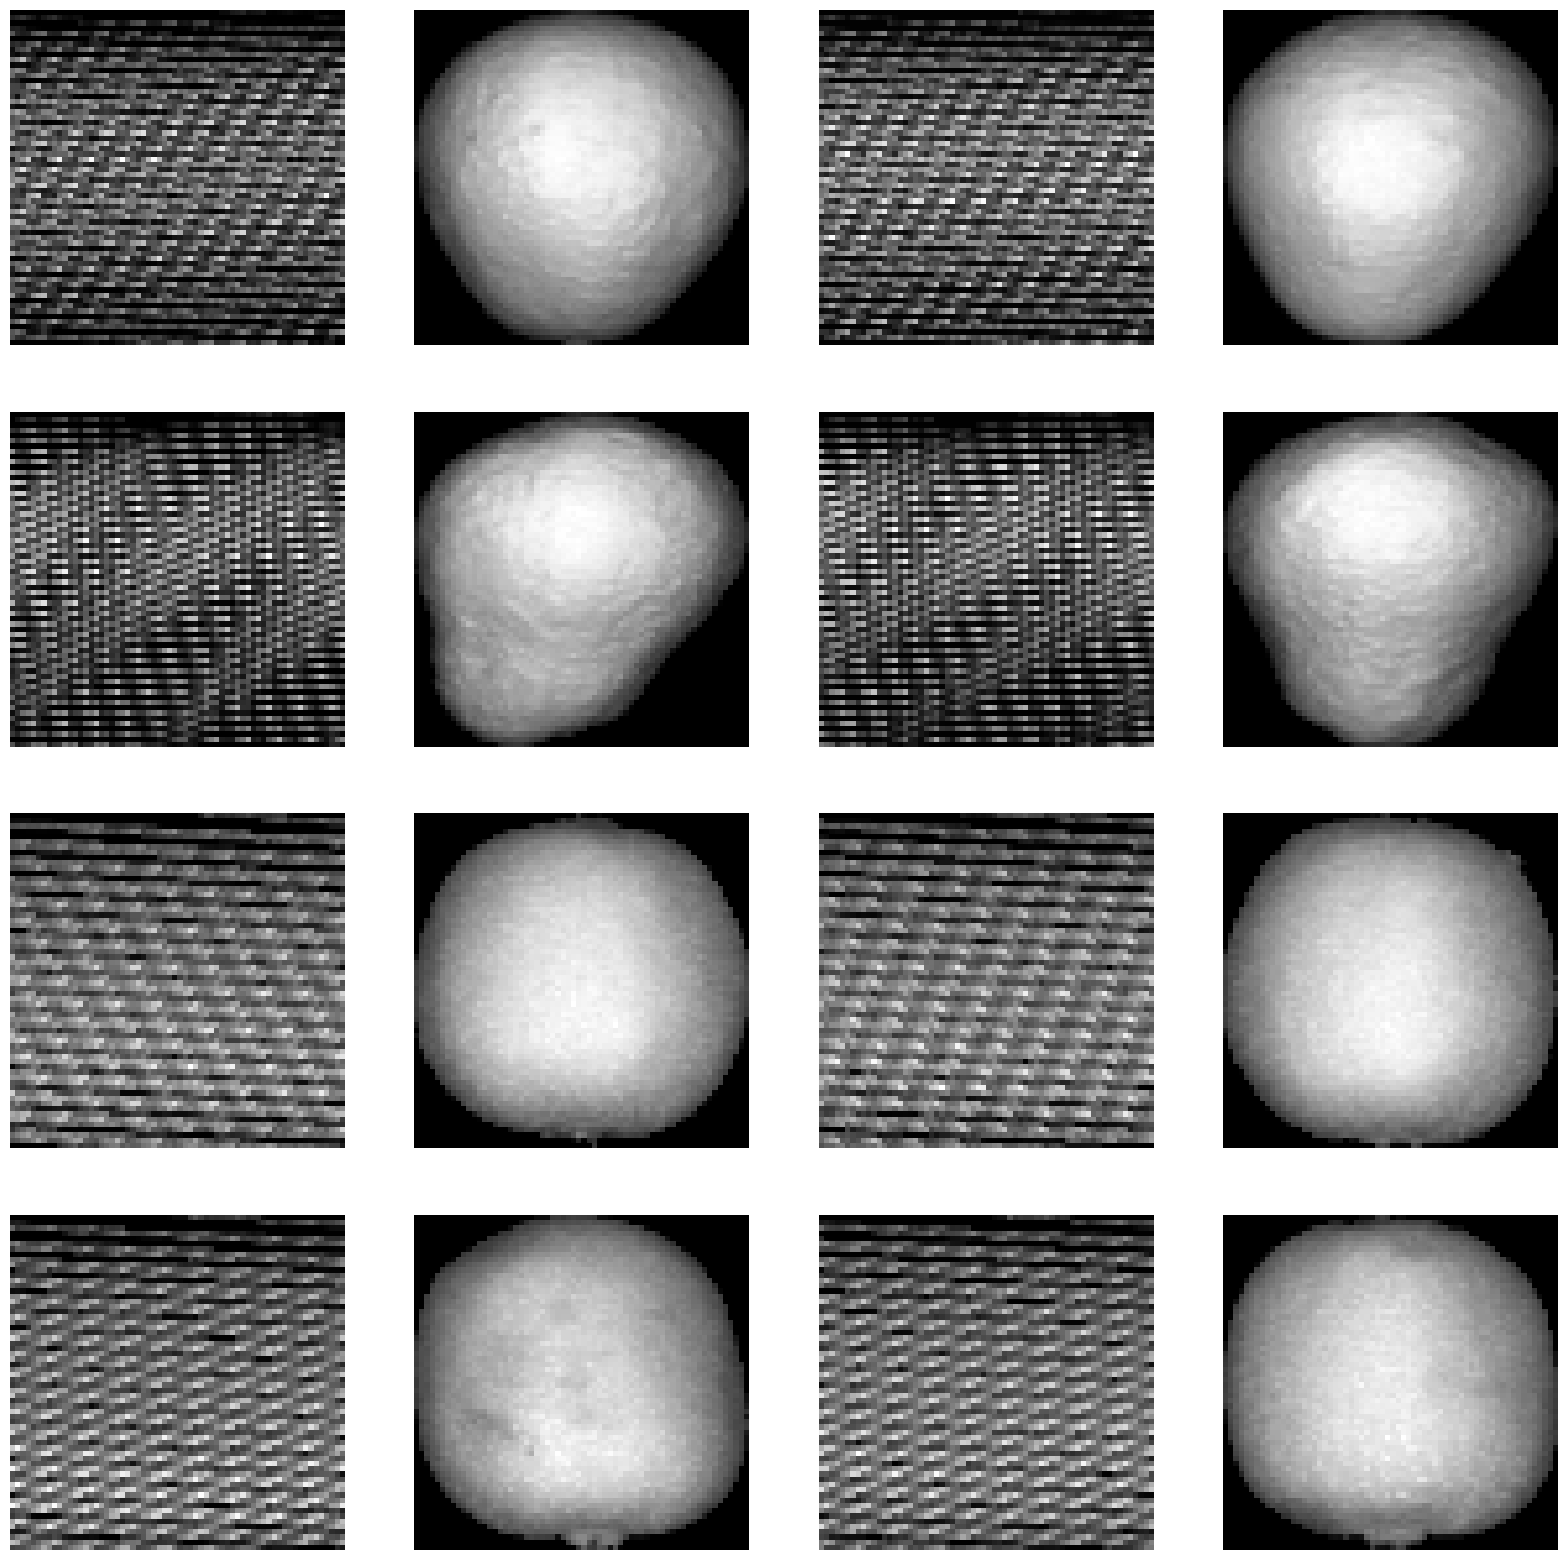

In [14]:
from sklearn.preprocessing import StandardScaler
from net.hsi_sequence import HyperspectralSequence
import matplotlib.pyplot as plt
import numpy as np

selected_fruits = ['Mango', 'Kaki','Papaya', 'Kiwi', 'Avocado']

batch_size = 32
max_bands = 224

hsi_train_sequence = HyperspectralSequence(training_annotations, DeepHS_dir, selected_fruits, batch_size, max_bands)
hsi_val_sequence = HyperspectralSequence(validation_annotations, DeepHS_dir, selected_fruits, batch_size, max_bands)
hsi_test_sequence = HyperspectralSequence(test_annotations, DeepHS_dir, selected_fruits, batch_size, max_bands)

print("Batch size:", hsi_train_sequence.batch_size)
print("Selected fruits:", hsi_train_sequence.selected_fruits)
print("Total batches:", len(hsi_train_sequence))

# Single batch of data
X_batch, _ = hsi_train_sequence[0]  
print("Shape of X_batch:", X_batch.shape)

def plot_band(X_batch, band_number):
    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    for i, ax in enumerate(axes.flat):
        ax.imshow(X_batch[i, :, :, band_number, 0], cmap='gray')
        ax.axis('off')
    plt.show()

plot_band(X_batch, 189)

In [15]:
from net.hsi_net import hsi_3dAE
print(X_batch.shape[1:])

hsi_3D_AE, hsi_latent = hsi_3dAE(input_shape=X_batch.shape[1:])
hsi_3D_AE.compile(optimizer='adam', loss='mean_squared_error')
hsi_3D_AE.summary()

(64, 64, 224, 1)


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 224, 1) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 64, 64, 224,    │           588 │
│                                 │ 21)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 64, 64, 224,    │         1,859 │
│                                 │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 64, 64, 224, 7) │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 802816)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │   102,760,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 802816)         │     2,408,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling3d (UpSampling3D)    │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding3d (ZeroPadding3D)  │ (None, 65, 65, 225, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cropping3d (Cropping3D)         │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose                │ (None, 64, 64, 224, 7) │            56 │
│ (Conv3DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_1              │ (None, 64, 64, 224,    │           627 │
│ (Conv3DTranspose)               │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_2              │ (None, 64, 64, 224, 1) │           298 │
│ (Conv3DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,181,330 (401.23 MB)

 Trainable params: 105,181,330 (401.23 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
hsi_3D_AE.fit(hsi_train_sequence, validation_data=hsi_val_sequence, verbose=1, epochs=10)

Epoch 1/10


/Users/jw/.pyenv/versions/bnjo_net/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


KeyboardInterrupt: 

In [ ]:
hsi_3D_AE.save(f'models/hsi_3D_AE{selected_fruits}.keras')

## CCA_DCCA

In [17]:
from net.cca_dcca_net import CCA_DCCA

print(X_batch.shape)
print(spectra_input_shape)

# Need to further define the CCA_DCCA model or consider something else like VAE
cca_dcca_model = CCA_DCCA(hsi_input_shape=X_batch.shape[1:], spectral_input_shape=spectra_input_shape)
cca_dcca_model.compile(optimizer='adam')

(32, 64, 64, 224, 1)
(224, 1)


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 224, 1) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 64, 64, 224,    │           588 │
│                                 │ 21)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 64, 64, 224,    │         1,859 │
│                                 │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 64, 64, 224, 7) │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 802816)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │   102,760,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 802816)         │     2,408,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling3d_1 (UpSampling3D)  │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding3d_1                │ (None, 65, 65, 225, 7) │             0 │
│ (ZeroPadding3D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cropping3d_1 (Cropping3D)       │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_3              │ (None, 64, 64, 224, 7) │            56 │
│ (Conv3DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_4              │ (None, 64, 64, 224,    │           627 │
│ (Conv3DTranspose)               │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_5              │ (None, 64, 64, 224, 1) │           298 │
│ (Conv3DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,181,330 (401.23 MB)

 Trainable params: 105,181,330 (401.23 MB)

...

Model: "cca_dcca__model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_5 (Functional)       │ ?                      │   105,181,330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_7 (Functional)       │ ?                      │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,182,435 (401.24 MB)

 Trainable params: 105,182,435 (401.24 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
from tensorflow.keras.callbacks import TensorBoard
import datetime

log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)

ValueError: Unrecognized data type: x=[<net.hsi_sequence.HyperspectralSequence object at 0x343fde410>, array([[[-0.27075608],
        [-0.27076414],
        [-0.27067007],
        ...,
        [ 0.62974429],
        [ 0.57304009],
        [ 0.44793063]],

       [[-0.0077137 ],
        [-0.00754335],
        [-0.007305  ],
        ...,
        [-1.43747836],
        [-1.43954193],
        [-1.43460079]],

       [[-0.02675376],
        [-0.02690363],
        [-0.0268459 ],
        ...,
        [-0.29761018],
        [-0.28134166],
        [-0.26811544]],

       ...,

       [[-0.06389168],
        [-0.06455625],
        [-0.06512724],
        ...,
        [-1.40508064],
        [-1.40827183],
        [-1.41182838]],

       [[-0.00361384],
        [-0.00293074],
        [-0.0026783 ],
        ...,
        [-1.0492919 ],
        [-1.05458656],
        [-1.08369089]],

       [[-0.01452547],
        [-0.01527119],
        [-0.01592442],
        ...,
        [-1.2862828 ],
        [-1.29